# C200-always: the full ML pipeline without the confidence layer

This notebook walks through every stage of the CISCaRL pipeline on a simulated
dataset with a **known subgroup**, then runs the **same 40 replications** used in
the Gate 28 C200-vs-SCRE head-to-head, and a **1,000-rep C200-always sweep**.

- **C200-always**: select a leaf and always treat it (no confidence/LCB layer).
- **SCRE**: comparator on the same assessment patients.
- **SCRE**: comparator on the same assessment patients.

Stages: data → simulation DGP → split → Cox nuisances → AIPW ψ → CART → support
and selection → validation → commit vs always → assessment → 40-rep summary.


In [1]:
import sys, json, contextlib, io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "ciscarl2").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from ciscarl2 import dgp
from ciscarl2.estimators import aipw, crossfit_nuisances, phi_on_holdout
from ciscarl2.gate2 import pseudo_outcome
from ciscarl2.gate4 import scre_select_alpha
from ciscarl2.gate4d import TSTAR, _delta_for
from ciscarl2.gate11 import _cart
from ciscarl2.gate19 import _assign_effs, _leaf_table
from ciscarl2.gate20 import _capped_G
from ciscarl2.gate22 import _stats
from ciscarl2.gate23 import E1, E2, _config23, _regions
from ciscarl2.gate26 import _calibrate_kind, _sim_kind
from ciscarl2.gate28 import _metrics
from ciscarl2.rules import eval_rule, rule_str

try:
    from ciscarl2.external.scre import SurvivalCausalRuleEnsemble
except Exception:
    SurvivalCausalRuleEnsemble = None

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
print("repo :", ROOT)
print("numpy:", np.__version__, "| pandas:", pd.__version__)


repo : C:\Users\sanje\OneDrive\Desktop\Amrita\Sem 5\ML\project_ML\ciscarl_c200\ciscarl
numpy: 2.2.2 | pandas: 2.3.3


## Stage 1 — the real dataset

We start from the ACTG175 cohort used in the project (arms 0/1, 1,054 patients)
to show the data structure. The pipeline below is then run on a simulated
8,000-patient dataset so the true subgroup is known.


In [2]:
raw = pd.read_csv(ROOT / "data" / "ACTG175.csv")
d = raw[raw.arms.isin([0, 1])].reset_index(drop=True)
print("full ACTG175:", raw.shape, "| arms 0/1:", d.shape)
print("events:", int(d.cens.sum()), f"({100 * d.cens.mean():.1f}%)")
print("censored before 730:", int(((d.days <= 730) & (d.cens == 0)).sum()))
print("at risk at 730:", int((d.days > 730).sum()))
d[["cd40", "cd80", "age", "wtkg", "karnof", "days", "cens"]].describe().round(1)


full ACTG175: (2139, 27) | arms 0/1: (1054, 27)
events: 284 (26.9%)
censored before 730: 103
at risk at 730: 750


,cd40,cd80,age,wtkg,karnof,days,cens
count,1054.0,1054.0,1054.0,1054.0,1054.0,1054.0,1054.0
mean,351.0,995.7,35.2,75.5,95.5,858.2,0.3
std,122.3,481.4,8.8,13.4,5.9,302.9,0.4
min,0.0,40.0,12.0,31.0,70.0,33.0,0.0
25%,264.2,654.0,29.0,67.1,90.0,647.2,0.0
50%,340.0,894.5,34.0,74.5,100.0,989.0,0.0
75%,423.8,1214.5,40.0,83.0,100.0,1090.0,1.0
max,1199.0,4255.0,70.0,159.9,100.0,1231.0,1.0


## Stage 2 — simulation DGP and the three splits

Single-region DGP: `cd40 < median & age > median` gets **+0.20** in S(730).
The data are split 4,000 discovery / 2,000 validation / 2,000 assessment.


In [3]:
from sklearn.model_selection import train_test_split

cfg = _config23()
lam = _calibrate_kind(cfg, "single")
seed = 300100
rng = np.random.RandomState(seed)
n = 8000
pool, mu_, sd_, cuts, idx, lam0 = cfg

X = pool[rng.choice(len(pool), n, replace=True)]
R1, R2 = _regions(X, cfg)
R2 = np.zeros(n, bool)
union = R1 | R2
lp0 = X @ dgp.BETA
s0 = np.exp(-lam0 * TSTAR * np.exp(lp0))
e1 = np.where(R1, _delta_for(E1, s0), 0.0)
e2 = np.where(R2, _delta_for(E2, s0), 0.0)
A = rng.binomial(1, 0.5, n)
sim = _sim_kind(X, A, lam, lam0, rng, e1, e2)
T, E = sim["Tobs"], sim["E"]
truth = sim["S1"] - sim["S0"]

ii = np.arange(n)
disc, hold = train_test_split(ii, test_size=0.5, random_state=seed, stratify=A)
val, asm = train_test_split(hold, test_size=0.5, random_state=seed + 1,
                            stratify=A[hold])
XD, AD, TD, ED = X[disc], A[disc], T[disc], E[disc]
XV, AV, TV, EV = X[val], A[val], T[val], E[val]
XA, AA, TA, EA = X[asm], A[asm], T[asm], E[asm]
truthA, uniA = truth[asm], union[asm]

print("n:", n, "| events:", int(E.sum()))
print("discovery:", len(disc), "validation:", len(val), "assessment:", len(asm))
print("true region prevalence (assessment):", round(float(uniA.mean()), 3))


n: 8000 | events: 4886
discovery: 4000 validation: 2000 assessment: 2000
true region prevalence (assessment): 0.267


## Stage 3 — cross-fitted Cox nuisances

- Outcome model: per-arm Cox, 5-fold cross-fitting → `μ₀(x), μ₁(x)`.
- Censoring model: conditional Cox → `G(x)`.
- The weight cap is derived from training folds only.


In [4]:
muD, GD, Gmarg, fid, fcaps, _ = crossfit_nuisances(
    XD, AD, TD, ED, TSTAR, seed=seed, return_folds=True)
G = _capped_G(muD, GD, Gmarg, fid, fcaps, "conditional", TD)

print("muD shape:", muD.shape, "| G shape:", G.shape)
print(pd.DataFrame({"mu0": muD[:, 0], "mu1": muD[:, 1], "G": G}).describe().round(3))


muD shape: (4000, 2) | G shape: (4000,)
            mu0       mu1         G
count  4000.000  4000.000  4000.000
mean      0.748     0.813     0.871
std       0.173     0.131     0.075
min       0.013     0.053     0.653
25%       0.672     0.759     0.832
50%       0.801     0.859     0.892
75%       0.877     0.904     0.928
max       0.991     0.982     0.989


## Stage 4 — the AIPW pseudo-outcome ψ

```
Y_ipcw = 1{Tobs > 730} / G
ψ = (A - e)/(e(1-e)) · (Y_ipcw - μ_A) + (μ₁ - μ₀),  e = 0.5
```

`ψ` is a per-patient, doubly-robust estimate of `τ(x)`. It is noisy at the
patient level, which is why the tree averages it inside leaves.


count    4000.000
mean        0.052
std         1.008
min        -2.336
25%        -0.669
50%         0.213
75%         0.792
max         2.587
dtype: float64


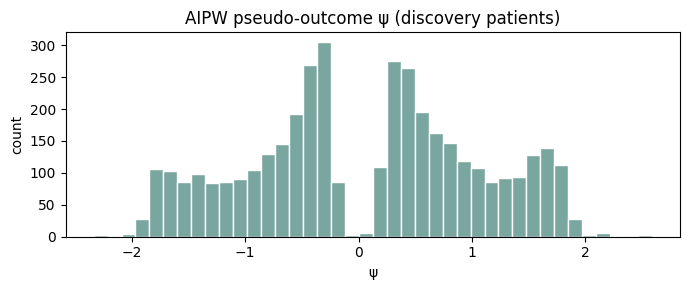

In [5]:
psi = pseudo_outcome(AD, TD, TSTAR, muD, G)
print(pd.Series(psi).describe().round(3))

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(psi, bins=40, color="#7aa6a0", edgecolor="white")
ax.set_title("AIPW pseudo-outcome ψ (discovery patients)")
ax.set_xlabel("ψ")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()


## Stage 5 — discovery CART

Depth 3, `min_samples_leaf=60`, squared error. Each leaf is a readable rule and
has a mean ψ.


In [6]:
leaves = _cart(psi, XD, 3)[1]
means, ses, sup = _stats(psi, leaves)
leaf_df = pd.DataFrame({
    "leaf": range(1, len(leaves) + 1),
    "rule": [rule_str(r["cond"], dgp.COVARIATES) for r in leaves],
    "support": sup.astype(int),
    "mean_psi": means,
})
display(leaf_df.round(3))


,leaf,rule,support,mean_psi
0,1,cd40 <= -0.200 & age <= 0.487,1314,0.046
1,2,cd40 <= -0.118 & cd40 > -0.200 & age <= 0.487,71,0.388
2,3,cd40 <= -1.206 & age > 0.487,99,-0.032
3,4,cd40 <= -0.118 & cd40 > -1.206 & age > 0.487,480,0.270
4,5,cd40 > -0.118 & wtkg <= -1.223,178,0.054
5,6,cd40 > -0.118 & wtkg <= -0.998 & wtkg > -1.223,76,0.346
6,7,cd40 <= -0.045 & cd40 > -0.118 & wtkg > -0.998,116,-0.205
7,8,cd40 > -0.045 & wtkg > -0.998,1666,-0.011


## Stage 6 — support floor and selection

Pick the leaf with the largest discovery mean ψ **among leaves with support
≥ 200**. If none qualify, take the best available leaf and flag the fallback.


In [7]:
ok = sup >= 200
fallback = not bool(ok.any())
j = (int(np.nanargmax(np.where(ok, means, -np.inf))) if ok.any()
     else int(np.nanargmax(means)))
print("selected leaf:", j + 1)
print("rule         :", rule_str(leaves[j]["cond"], dgp.COVARIATES))
print("support      :", int(sup[j]))
print("fallback     :", fallback)


selected leaf: 4
rule         : cd40 <= -0.118 & cd40 > -1.206 & age > 0.487
support      : 480
fallback     : False


## Stage 7 — validation effect (no LCB gate)

The selected leaf is re-estimated on the disjoint validation patients.
C200-always reports the effect and SE but does **not** use the LCB to decide.


In [8]:
p1v, p0v = phi_on_holdout(XD, AD, TD, ED, XV, AV, TV, TSTAR, seed=seed)
dphi_v = p1v - p0v
const = float(aipw(XD, AD, TD, TSTAR, muD, G)[0])
tbl_v = _leaf_table(leaves, XV, dphi_v)
effs = np.array([t["eff"] for t in tbl_v], float)
ses_v = np.array([t["se"] for t in tbl_v], float)
effs = np.where(np.isfinite(effs), effs, const)

mv = eval_rule(leaves[j]["cond"], XV)
kv = int(mv.sum())
hi_eff = float(dphi_v[mv].mean()) if kv else np.nan
hi_se = (float(np.sqrt(((dphi_v[mv] - hi_eff) ** 2).sum()) / kv)
         if kv else np.nan)
print(f"validation effect: {hi_eff:+.3f}")
print(f"validation SE    : {hi_se:.3f}")
print("C200-always: always treat the selected leaf (no LCB gate).")


validation effect: +0.165
validation SE    : 0.073
C200-always: always treat the selected leaf (no LCB gate).


## Stage 8 — assessment metrics for this replication

We score C200-always on the untouched assessment patients, and fit SCRE on the
same discovery data for comparison.


In [9]:
masks_a = [eval_rule(r["cond"], XA) for r in leaves]

tbl_a = [dict(cond=leaves[t]["cond"], mask=masks_a[t],
              eff=effs[t], se=ses_v[t]) for t in range(len(leaves))]
pred_a = _assign_effs(tbl_a, XA, effs, const)
treated_a = masks_a[j]

mc_a = _metrics(pred_a, treated_a, truthA, uniA)
display(pd.DataFrame([{"method": "C200-always", **mc_a}]).round(3))

if SurvivalCausalRuleEnsemble is not None:
    s = SurvivalCausalRuleEnsemble(
        alpha=0.5, pred_n_estimators=100, progn_n_estimators=100,
        rule_min_support=20, max_rules=200, max_rule_conditions=3,
        max_selected_rules=10, random_state=42)
    with contextlib.redirect_stdout(io.StringIO()):
        s.fit(XD, psi, np.isfinite(psi),
              feature_names=[f"x{i}" for i in range(XD.shape[1])],
              time=TD, event=ED.astype(bool), treatment=AD)
        pick = scre_select_alpha(s, XV, AV, TV, EV.astype(bool), TSTAR)
    if pick is not None:
        s.alpha_ = s.alpha_final_ = pick[1]
        s.coef_ = pick[2]
    s.t_star_ = TSTAR
    with contextlib.redirect_stdout(io.StringIO()):
        tau_s = np.asarray(s.predict(XA), float)
    mc_s = _metrics(tau_s, tau_s > 0, truthA, uniA)
    display(pd.DataFrame([{"method": "SCRE", **mc_s}]).round(3))


,method,mae,spearman,capture,purity,per_treated,efficiency,null,coverage
0,C200-always,0.049,0.668,0.506,1.0,0.198,0.989,False,0.132


,method,mae,spearman,capture,purity,per_treated,efficiency,null,coverage
0,SCRE,0.053,0.609,0.936,0.473,0.091,0.936,False,0.53


## Stage 9 — 40-rep results: C200-always vs SCRE

This recomputes 40 replications × 2 DGPs with the same seeds (300100–300139).
If parallel execution is unavailable, it falls back to `results/always_treat.csv`.


recomputed 40 reps x 2 DGPs


,kind,method,reps,mae,purity,capture,per_treated,coverage,null_rate
0,single,C200-always,40,0.056,0.834,0.627,0.163,0.187,0.0
1,single,SCRE,40,0.052,0.433,0.947,0.084,0.544,0.0
2,two,C200-always,40,0.071,0.847,0.374,0.163,0.157,0.0
3,two,SCRE,40,0.068,0.585,0.802,0.098,0.560,0.0


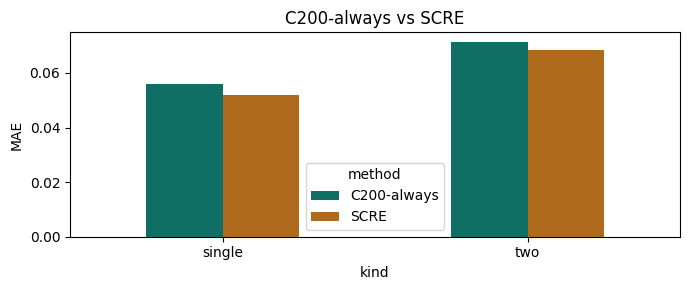

In [10]:
from joblib import Parallel, delayed
from c200_always import run_rep

cfg_all = _config23()
lam_all = {k: _calibrate_kind(cfg_all, k) for k in ("single", "two")}

try:
    out = Parallel(n_jobs=8, verbose=0)(
        delayed(run_rep)(r, k, cfg_all, lam_all[k])
        for k in ("single", "two") for r in range(40))
    res = pd.DataFrame([x for ch in out for x in ch])
    res.to_csv(ROOT / "results" / "always_treat.csv", index=False)
    print("recomputed 40 reps x 2 DGPs")
except Exception as exc:
    print("parallel recompute unavailable, loading saved run:", repr(exc))
    res = pd.read_csv(ROOT / "results" / "always_treat.csv")

agg = (res.groupby(["kind", "method"])
       .agg(reps=("rep", "size"), mae=("mae", "mean"),
            purity=("purity", "mean"), capture=("capture", "mean"),
            per_treated=("per_treated", "mean"),
            coverage=("coverage", "mean"),
            null_rate=("null", lambda s: 100 * s.mean()))
       .reset_index())
display(agg.round(3))

pivot = agg.pivot(index="kind", columns="method", values="mae")
pivot.plot.bar(figsize=(7, 3), rot=0, color=["#0f6f64", "#b06a1e"])
plt.ylabel("MAE")
plt.title("C200-always vs SCRE")
plt.tight_layout()
plt.show()


## Stage 10 — 1,000-rep C200-always sweep

No confidence layer, 1,000 replications on the two-region DGP (seeds
340100–341099). This is the stable operating point: purity, capture,
per-treated benefit, coverage, null rate, and MAE.


In [11]:
sweep = pd.read_csv(ROOT / "results" / "always_sweep_1000_two_summary.csv")
display(sweep.T.rename(columns={0: "C200-always"}))


,C200-always
design,two-region DGP
method,C200-always
n,8000
reps,1000
seeds,340100-341099
commit,100.0
fallback,0.0
support,680.774
purity,0.813906
capture,0.365422


## What the notebook shows

- The pipeline is a **regression** problem: the CART is trained on the continuous
  pseudo-outcome ψ, not on a class label.
- C200-always always treats the selected leaf; there is no abstention/LCB layer.
- Across 40 reps it is compared with SCRE on the same assessment patients.
- At 1,000 reps, the C200-always operating point is stable (purity, capture,
  per-treated benefit, null rate).
- SCRE treats far more patients and captures more total benefit, but is much less
  pure; C200-always remains the high-purity, low-coverage point on the frontier.

**Bottom line:** C200-always is a precision-oriented policy; SCRE is a
coverage-oriented one. Neither dominates.
